## Test Scenario 1: 
Hanging a light fixture above a stage


<img src="images/Stage.png" style = "width:960px;height:540px">


## Geometric Representation:

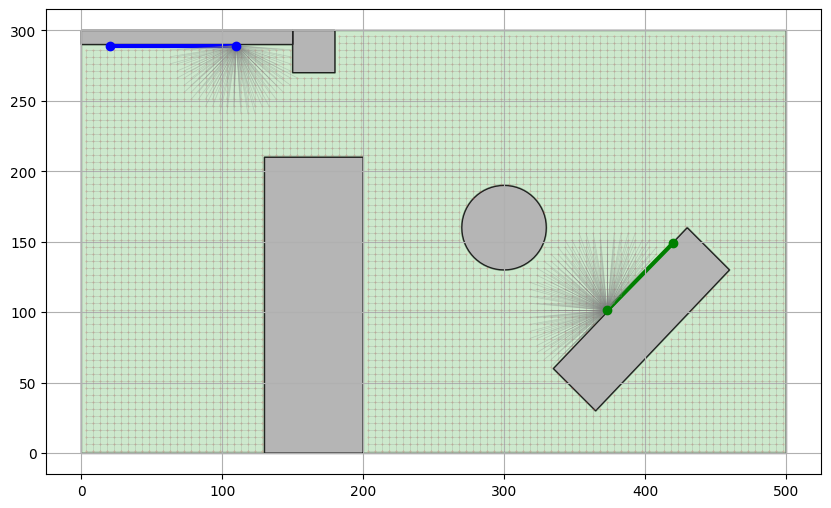

In [1]:
from evo_pathfinding_gen_sm.genetic_algorithm.evolution import Evolution_Manager  
from evo_pathfinding_gen_sm.geometry import Environment, Mount
from evo_pathfinding_gen_sm.rendering.renderer import render_environment, render_fitness_graph

import shapely


mount1_plate = shapely.geometry.LineString([(110, 289), (20, 289)])
mount2_plate = shapely.geometry.LineString([(373, 101.5), (420, 149.5)])



env = Environment(
    area=(0, 0, 500, 300),
    obstacles=[
        shapely.geometry.Polygon([ (430, 160),(460, 130), (365, 30), (335, 60)]),
        shapely.geometry.box(0, 300, 150, 290),
        shapely.geometry.box(130, 0, 200, 210),
        shapely.geometry.box(150, 300, 180, 270),
        shapely.geometry.Point(300, 160).buffer(30),


    ],
    mount1=Mount(mount1_plate.coords[0], mount1_plate.coords[1], thickness=0.5),
    mount2=Mount(mount2_plate.coords[0], mount2_plate.coords[1], thickness=0.5),
    thickness=0.5
)

test_evolution = Evolution_Manager(
    environment=env,)

render_environment(env)

In [3]:
fitness_offset=25
test_evolution.run_evolution(generations_count=8,population_size=8,pathfinder_type='PRM', selection_type='rank',fitness_offset=fitness_offset)


No path found
No path found
Generation 0 completed.
 Best fitness: -6.43853126818432
Generation 1 completed.
 Best fitness: 2.1788697623295334
Generation 2 completed.
 Best fitness: 2.1788697623295334
Generation 3 completed.
 Best fitness: 2.1788697623295334
Generation 4 completed.
 Best fitness: 2.2577613836966286
Generation 5 completed.
 Best fitness: 2.2577613836966286
Generation 6 completed.
 Best fitness: 2.2577613836966286
Generation 7 completed.
 Best fitness: 2.3391742619060203
Generation 8 completed.
 Best fitness: 2.3391742619060203


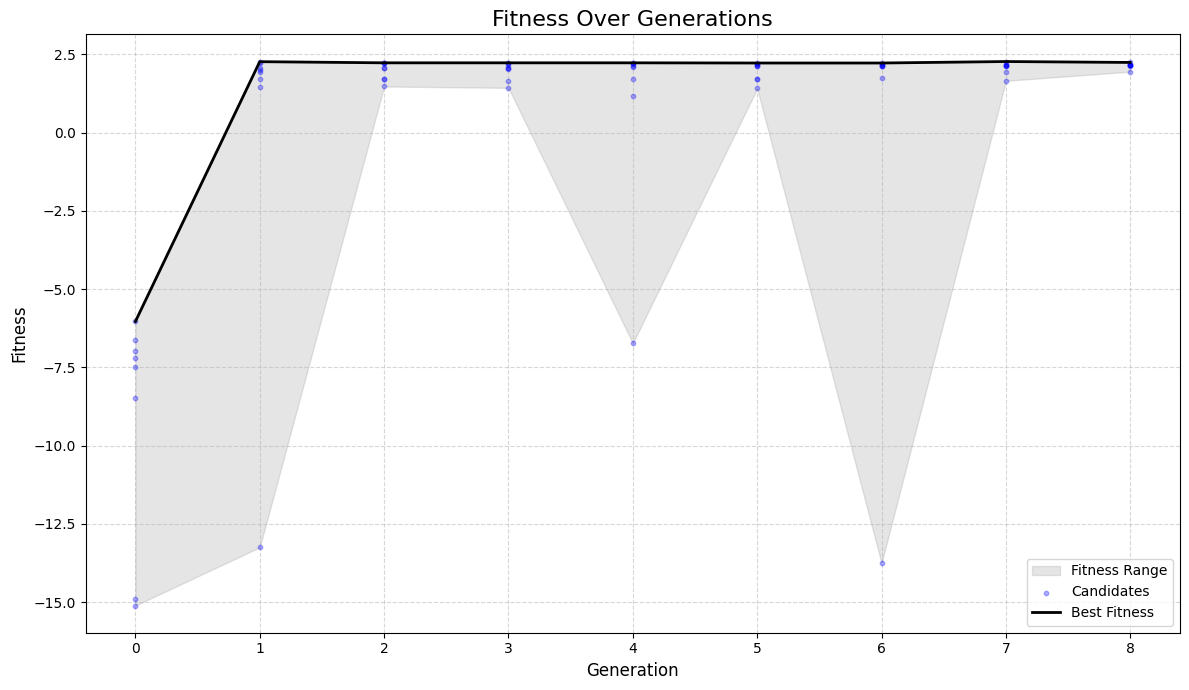

In [ ]:
render_fitness_graph(test_evolution.generations,fitness_offset=fitness_offset)

## Best Candidate:

Best overall fitness: 2.267608736495191 at generation 7 of 9


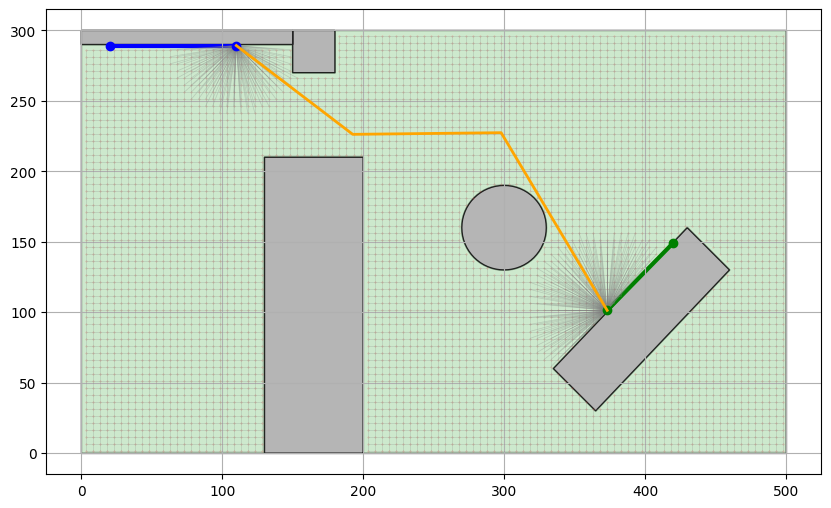

In [ ]:
# render the best phenotype amongst all generations
best_overall_phenotype = None
best_fitness = float('-inf')
for i, generation in enumerate(test_evolution.generations):
    if generation.best_phenotype.fitness > best_fitness:
        best_fitness = generation.best_phenotype.fitness
        best_overall_phenotype = generation.best_phenotype
        best_generation_index = i
print(f"Best overall fitness: {best_fitness + fitness_offset } at generation { best_generation_index } of {len(test_evolution.generations)}")
render_environment(env, best_overall_phenotype.nodes)